# Remaining Useful Life (RUL) Prediction of Turbofan Engines
**Project 10 – Rolls-Royce Aerospace | UCS321 EST Mini Project**

Dataset: NASA C-MAPSS (FD001). Models: Random Forest baseline, SimpleRNN, LSTM, GRU, Bidirectional LSTM.

**Pipeline:** Load → EDA → Preprocess (RUL label + cap, drop flat sensors, scale, sliding window, engine-wise split) → Train → Evaluate (RMSE, MAE, R², NASA score) → Visualize → Maintenance logic

In [1]:
!pip -q install kagglehub
import os, glob, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
warnings.filterwarnings('ignore')
SEED=42; np.random.seed(SEED); tf.random.set_seed(SEED); random.seed(SEED)
sns.set_style('whitegrid')

## 1. Load data

In [2]:
# Option A: download from Kaggle mirror automatically
path=None
try:
    import kagglehub
    root=kagglehub.dataset_download("behrad3d/nasa-cmaps")
    hits=glob.glob(root+'/**/train_FD001.txt', recursive=True)
    path=os.path.dirname(hits[0]) if hits else None
except Exception as e:
    print('Auto-download failed:', e)

# Option B: manual upload of train_FD001.txt, test_FD001.txt, RUL_FD001.txt
if path is None:
    from google.colab import files
    files.upload(); path='.'
print('Data folder:', path)

cols=['unit','cycle','op1','op2','op3']+[f's{i}' for i in range(1,22)]
train=pd.read_csv(f'{path}/train_FD001.txt', sep=r'\s+', header=None, names=cols)
test =pd.read_csv(f'{path}/test_FD001.txt',  sep=r'\s+', header=None, names=cols)
rul_true=pd.read_csv(f'{path}/RUL_FD001.txt', header=None, names=['RUL'])
print(train.shape, test.shape, rul_true.shape)
train.head()

100%|██████████| 12.3M/12.3M [00:01<00:00, 6.86MB/s]

Extracting files...


Data folder: /root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps
(20631, 26) (13096, 26) (100, 1)


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2. Exploratory Data Analysis

0 missing values


,count,mean,std,min,25%,50%,75%,max
unit,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
op1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
op2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
op3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
s1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
s2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200


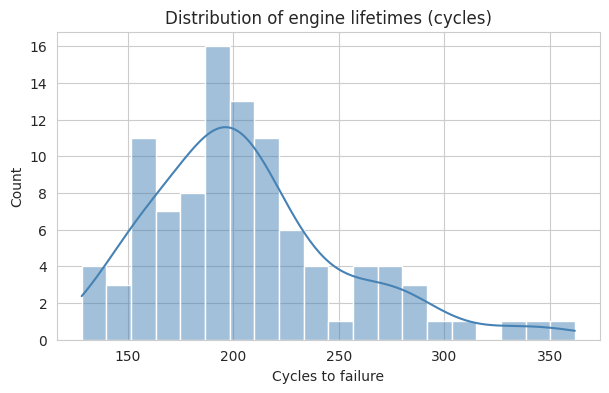

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


In [3]:
print(train.isnull().sum().sum(), 'missing values')
display(train.describe().T.head(26))
life=train.groupby('unit')['cycle'].max()
plt.figure(figsize=(7,4)); sns.histplot(life,bins=20,kde=True,color='steelblue')
plt.title('Distribution of engine lifetimes (cycles)'); plt.xlabel('Cycles to failure'); plt.show()
print(life.describe())

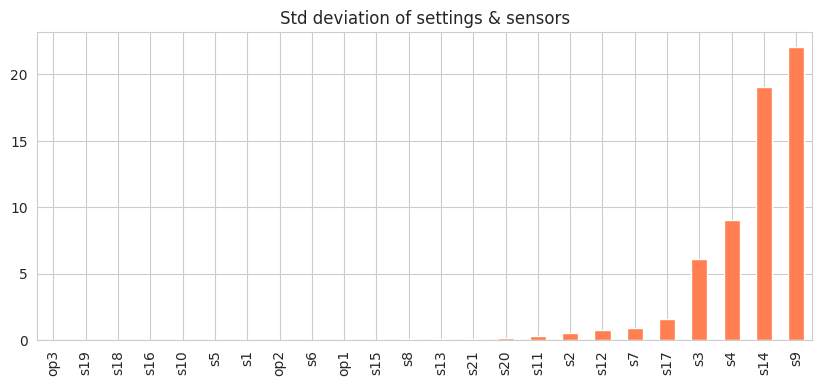

Constant columns to drop: ['op3', 's19', 's18', 's16', 's10', 's5', 's1', 'op2']


In [4]:
# Flat / low-variance sensors
std=train[cols[2:]].std().sort_values()
plt.figure(figsize=(10,4)); std.plot(kind='bar',color='coral'); plt.title('Std deviation of settings & sensors'); plt.show()
flat=std[std<1e-3].index.tolist(); print('Constant columns to drop:', flat)

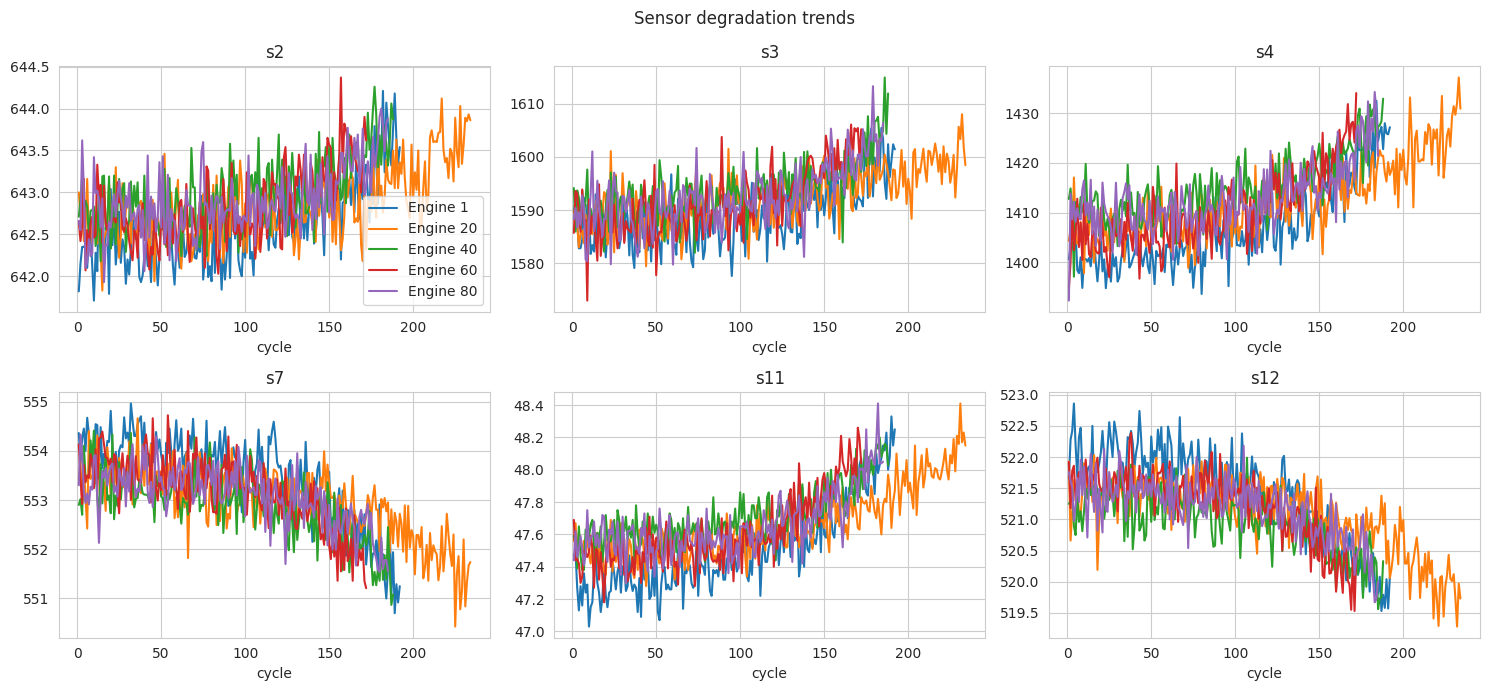

In [5]:
# Sensor trends for 5 engines
sens=['s2','s3','s4','s7','s11','s12']
fig,ax=plt.subplots(2,3,figsize=(15,7))
for a,s in zip(ax.ravel(),sens):
    for u in [1,20,40,60,80]:
        d=train[train.unit==u]; a.plot(d.cycle,d[s],label=f'Engine {u}')
    a.set_title(s); a.set_xlabel('cycle')
ax[0,0].legend(); plt.suptitle('Sensor degradation trends'); plt.tight_layout(); plt.show()

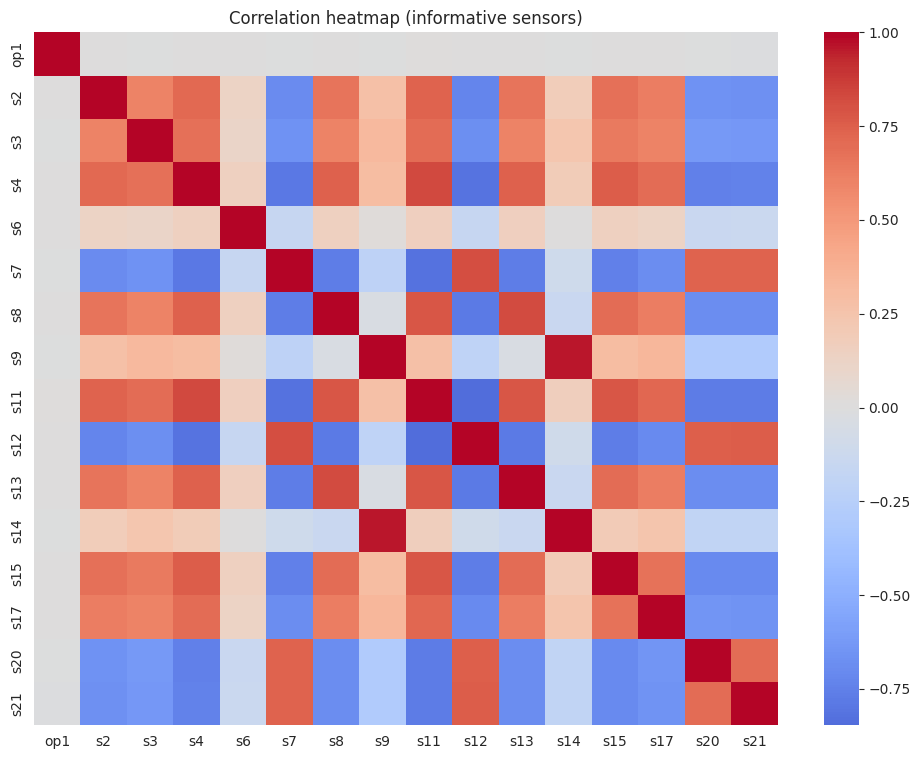

In [6]:
use=[c for c in cols[2:] if c not in flat]
plt.figure(figsize=(12,9)); sns.heatmap(train[use].corr(),cmap='coolwarm',center=0,annot=False)
plt.title('Correlation heatmap (informative sensors)'); plt.show()

## 3. Pre-processing

In [7]:
CAP=125; SEQ=30
# RUL label (piecewise-linear: capped at 125)
train['RUL']=train.groupby('unit')['cycle'].transform('max')-train['cycle']
train['RUL']=train['RUL'].clip(upper=CAP)

# keep informative sensors only (drop flat columns incl. op settings in FD001)
features=[c for c in cols[2:] if c not in flat]
print(len(features),'features used:',features)

# normalise (fit on train only)
scaler=MinMaxScaler()
train[features]=scaler.fit_transform(train[features])
test[features]=scaler.transform(test[features])

# sliding windows
def make_windows(df):
    X,y,u=[],[],[]
    for uid,g in df.groupby('unit'):
        a=g[features].values; r=g['RUL'].values
        for i in range(len(a)-SEQ+1):
            X.append(a[i:i+SEQ]); y.append(r[i+SEQ-1]); u.append(uid)
    return np.array(X,dtype='float32'),np.array(y,dtype='float32'),np.array(u)
X_all,y_all,u_all=make_windows(train)

# engine-wise split (no leakage)
engines=train.unit.unique(); rng=np.random.RandomState(SEED); val_eng=rng.choice(engines,15,replace=False)
vm=np.isin(u_all,val_eng)
X_tr,y_tr,X_val,y_val=X_all[~vm],y_all[~vm],X_all[vm],y_all[vm]

# test: last window per engine
X_te=[]
for uid,g in test.groupby('unit'):
    a=g[features].values
    if len(a)<SEQ: a=np.vstack([np.repeat(a[:1],SEQ-len(a),0),a])
    X_te.append(a[-SEQ:])
X_te=np.array(X_te,dtype='float32')
y_te=np.minimum(rul_true['RUL'].values,CAP).astype('float32')   # same cap as training
print('Train',X_tr.shape,'Val',X_val.shape,'Test',X_te.shape)

16 features used: ['op1', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
Train (15104, 30, 16) Val (2627, 30, 16) Test (100, 30, 16)


## 4. Evaluation helpers

In [8]:
def nasa_score(y,p):
    d=p-y
    return float(np.sum(np.where(d<0,np.exp(-d/13)-1,np.exp(d/10)-1)))
def evaluate(name,y,p):
    return {'Model':name,'RMSE':np.sqrt(mean_squared_error(y,p)),'MAE':mean_absolute_error(y,p),'R2':r2_score(y,p),'NASA Score':nasa_score(y,p)}
results=[]; preds={}

## 5. Models

In [9]:
# Baseline: Random Forest on flattened windows
rf=RandomForestRegressor(n_estimators=100,n_jobs=-1,random_state=SEED)
rf.fit(X_tr.reshape(len(X_tr),-1),y_tr)
p=rf.predict(X_te.reshape(len(X_te),-1)); preds['Random Forest']=p
results.append(evaluate('Random Forest',y_te,p)); results[-1]

{'Model': 'Random Forest',
 'RMSE': np.float64(16.14243575176931),
 'MAE': 12.035599999999997,
 'R2': 0.8377336660714536,
 'NASA Score': 634.2047673820381}

In [10]:
def build(kind):
    m=models.Sequential([layers.Input((SEQ,len(features)))])
    if kind=='SimpleRNN':
        m.add(layers.SimpleRNN(64,return_sequences=True)); m.add(layers.Dropout(0.2)); m.add(layers.SimpleRNN(32))
    elif kind=='LSTM':
        m.add(layers.LSTM(64,return_sequences=True)); m.add(layers.Dropout(0.2)); m.add(layers.LSTM(32))
    elif kind=='GRU':
        m.add(layers.GRU(64,return_sequences=True)); m.add(layers.Dropout(0.2)); m.add(layers.GRU(32))
    elif kind=='BiLSTM':
        m.add(layers.Bidirectional(layers.LSTM(64,return_sequences=True))); m.add(layers.Dropout(0.2)); m.add(layers.LSTM(32))
    m.add(layers.Dropout(0.2)); m.add(layers.Dense(32,activation='relu')); m.add(layers.Dense(1))
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss='mse',metrics=['mae'])
    return m

histories={}
for kind in ['SimpleRNN','LSTM','GRU','BiLSTM']:
    print('\n=== Training',kind,'===')
    m=build(kind)
    es=callbacks.EarlyStopping(monitor='val_loss',patience=8,restore_best_weights=True)
    rl=callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=4)
    h=m.fit(X_tr,y_tr,validation_data=(X_val,y_val),epochs=60,batch_size=128,callbacks=[es,rl],verbose=0)
    histories[kind]=h.history
    p=m.predict(X_te,verbose=0).ravel(); preds[kind]=p
    results.append(evaluate(kind,y_te,p)); print(results[-1])
    if kind=='LSTM': best_model=m


=== Training SimpleRNN ===
{'Model': 'SimpleRNN', 'RMSE': np.float64(13.560740835832), 'MAE': 9.74631404876709, 'R2': 0.885486364364624, 'NASA Score': 382.41131591796875}

=== Training LSTM ===
{'Model': 'LSTM', 'RMSE': np.float64(13.352795003272313), 'MAE': 9.858678817749023, 'R2': 0.8889714479446411, 'NASA Score': 324.8964538574219}

=== Training GRU ===


{'Model': 'GRU', 'RMSE': np.float64(13.814959414985458), 'MAE': 9.978507995605469, 'R2': 0.8811526298522949, 'NASA Score': 374.39422607421875}

=== Training BiLSTM ===
{'Model': 'BiLSTM', 'RMSE': np.float64(13.495114608114035), 'MAE': 9.73103141784668, 'R2': 0.8865920305252075, 'NASA Score': 383.61517333984375}


## 6. Results & visualization

,RMSE,MAE,R2,NASA Score
Model,,,,
Random Forest,16.142,12.036,0.838,634.205
SimpleRNN,13.561,9.746,0.885,382.411
LSTM,13.353,9.859,0.889,324.896
GRU,13.815,9.979,0.881,374.394
BiLSTM,13.495,9.731,0.887,383.615


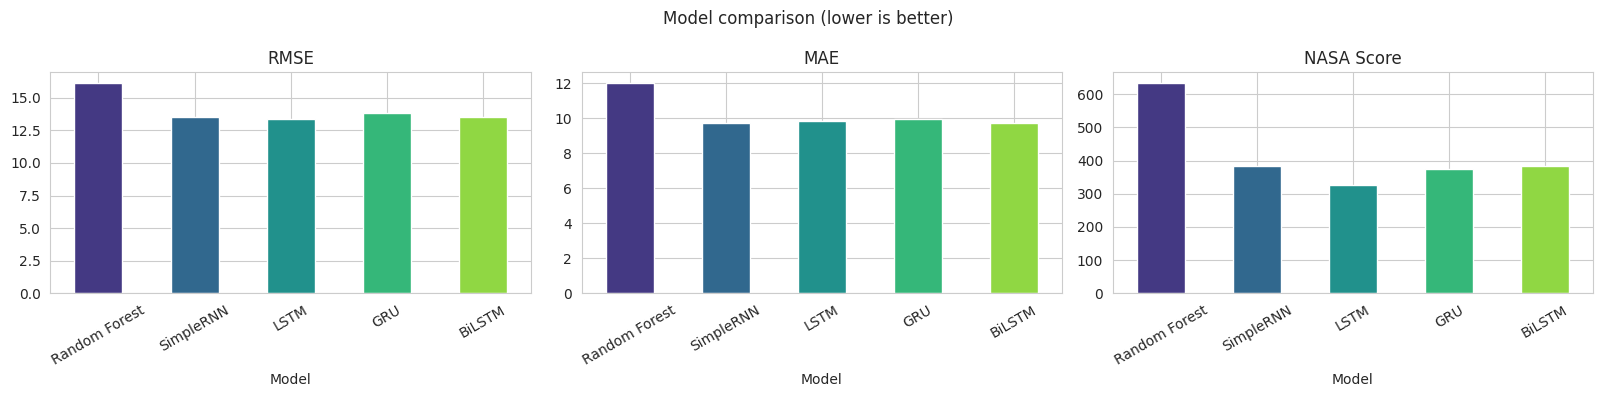

In [11]:
res=pd.DataFrame(results).set_index('Model').round(3); display(res)
fig,ax=plt.subplots(1,3,figsize=(16,4))
for a,c in zip(ax,['RMSE','MAE','NASA Score']):
    res[c].plot(kind='bar',ax=a,color=sns.color_palette('viridis',len(res))); a.set_title(c); a.tick_params(axis='x',rotation=30)
plt.suptitle('Model comparison (lower is better)'); plt.tight_layout(); plt.show()

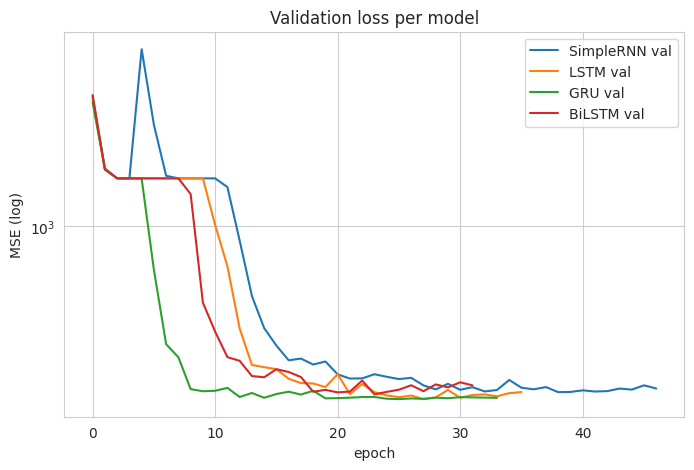

Best model: LSTM


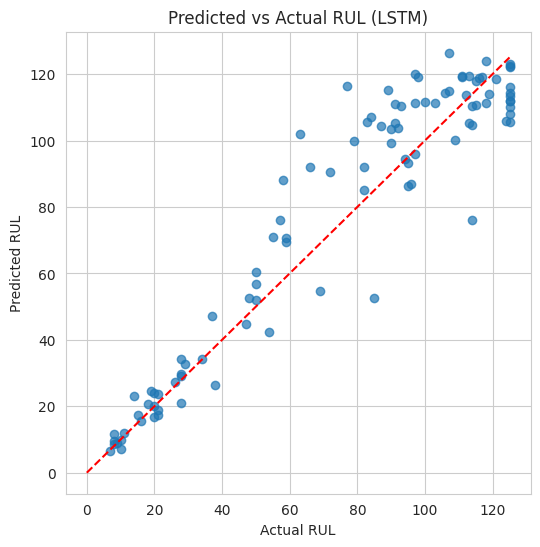

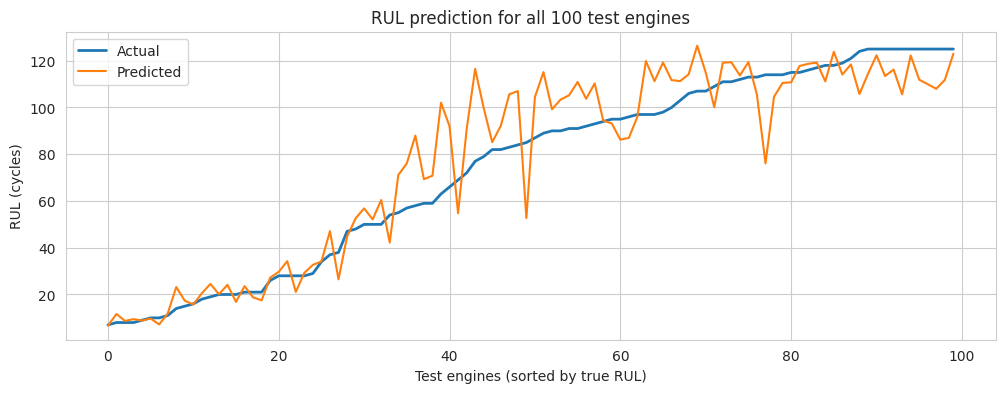

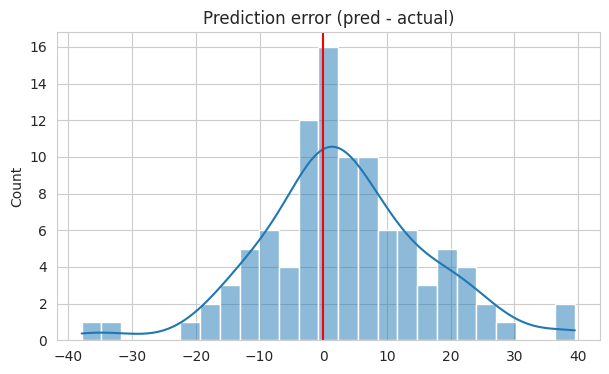

In [12]:
# Training curves
plt.figure(figsize=(8,5))
for k,h in histories.items():
    plt.plot(h['val_loss'],label=k+' val');
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('MSE (log)'); plt.title('Validation loss per model'); plt.legend(); plt.show()

# Predicted vs actual (best model by RMSE)
best=res['RMSE'].idxmin(); print('Best model:',best)
bp=preds[best]
plt.figure(figsize=(6,6)); plt.scatter(y_te,bp,alpha=.7); plt.plot([0,CAP],[0,CAP],'r--')
plt.xlabel('Actual RUL'); plt.ylabel('Predicted RUL'); plt.title(f'Predicted vs Actual RUL ({best})'); plt.show()

# Per-engine sorted comparison
o=np.argsort(y_te); plt.figure(figsize=(12,4))
plt.plot(y_te[o],label='Actual',lw=2); plt.plot(bp[o],label='Predicted',lw=1.5)
plt.xlabel('Test engines (sorted by true RUL)'); plt.ylabel('RUL (cycles)'); plt.legend(); plt.title('RUL prediction for all 100 test engines'); plt.show()

# Error distribution
plt.figure(figsize=(7,4)); sns.histplot(bp-y_te,bins=25,kde=True); plt.axvline(0,color='r'); plt.title('Prediction error (pred - actual)'); plt.show()

## 7. Maintenance scheduling logic

In [13]:
THRESH=30
alert=bp<THRESH; actual=y_te<THRESH
print(f'Engines flagged for maintenance (pred RUL < {THRESH}):', alert.sum(),'of',len(alert))
print(confusion_matrix(actual,alert)); print(classification_report(actual,alert,target_names=['OK','Maintain']))
sched=pd.DataFrame({'Engine':np.arange(1,len(bp)+1),'Pred_RUL':bp.round(1),'True_RUL':y_te})
sched['Priority']=pd.cut(sched.Pred_RUL,[-1,15,30,60,1000],labels=['CRITICAL','HIGH','MEDIUM','LOW'])
display(sched.sort_values('Pred_RUL').head(10)); print(sched.Priority.value_counts())

Engines flagged for maintenance (pred RUL < 30): 24 of 100
[[74  1]
 [ 2 23]]
              precision    recall  f1-score   support

          OK       0.97      0.99      0.98        75
    Maintain       0.96      0.92      0.94        25

    accuracy                           0.97       100
   macro avg       0.97      0.95      0.96       100
weighted avg       0.97      0.97      0.97       100



,Engine,Pred_RUL,True_RUL,Priority
33,34,6.600000,7.0,CRITICAL
41,42,7.200000,10.0,CRITICAL
80,81,8.700000,8.0,CRITICAL
81,82,8.800000,9.0,CRITICAL
67,68,9.500000,8.0,CRITICAL
75,76,9.700000,10.0,CRITICAL
30,31,11.700000,8.0,CRITICAL
34,35,11.800000,11.0,CRITICAL
19,20,15.700000,16.0,HIGH
99,100,16.799999,20.0,HIGH


Priority
LOW         65
HIGH        16
MEDIUM      11
CRITICAL     8
Name: count, dtype: int64


## 8. Conclusion
- Deep sequence models (LSTM/GRU/BiLSTM) outperform the Random Forest baseline because they learn temporal degradation patterns.
- Capping RUL at 125 and dropping constant sensors improves stability.
- Predicted RUL converts into a maintenance schedule (CRITICAL / HIGH / MEDIUM / LOW), reducing unplanned downtime.
- **Future work:** FD002–FD004 (multiple operating conditions), attention layers, Transformers, deployment as a dashboard.